# Etapa 2: Modelagem de Tópicos Neural (BERTopic) e Análise Longitudinal (2010–2024)

Neste notebook, avançamos para a etapa de **Mineração de Dados (Data Mining)** do processo KDD, com foco nos objetivos do artigo para o **Educomp**:
1. **Descoberta Não Supervisionada de Subáreas:** Agrupar semanticamente as teses e dissertações de Ciência da Computação no Brasil (2010–2024) usando representações neurais densas (*Sentence Embeddings* via PyTorch/Transformers) + redução de dimensionalidade (**UMAP**) + clusterização baseada em densidade (**HDBSCAN**).
2. **Rastreamento Temporal da Inteligência Artificial:** Mapear a evolução longitudinal dos tópicos ano a ano (`topics_over_time`) para detectar o ponto de inflexão das pesquisas em IA, Aprendizado de Máquina, Redes Neurais e Ciência de Dados.
3. **Análise de Disparidades Regionais e Nível Acadêmico:** Investigar como a produção em IA se distribui entre as regiões brasileiras (`NM_REGIAO`), instituições (`SG_ENTIDADE_ENSINO`) e graus acadêmicos (`NM_GRAU_ACADEMICO` - Mestrado vs. Doutorado).
4. **Rotulagem para Classificação Supervisionada:** Exportar a base enriquecida com os tópicos descobertos e a flag temática de IA para alimentar a Etapa 3 (modelos preditivos).

In [1]:
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style="whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo de execução PyTorch detectado: {device.upper()}")

Dispositivo de execução PyTorch detectado: CPU


## 1. Carregamento e Preparação da Base Pré-processada
Lemos a base compactada (`dados_capes_nlp_pronto.csv.gz`) gerada na Etapa 1. Como o BERTopic se beneficia tanto do contexto semântico das frases originais (`DS_RESUMO`) para gerar *embeddings* quanto do texto limpo/lematizado (`RESUMO_LIMPO`) para extrair representações de palavras (c-TF-IDF) sem ruído, garantimos que ambas as colunas estejam íntegras.

In [2]:
caminho_entrada = '../data/dados_capes_nlp.csv.gz'
df = pd.read_csv(caminho_entrada, compression='gzip')

# Remove eventuais linhas onde o resumo limpo tenha ficado vazio após o filtro rigoroso
df = df.dropna(subset=['DS_RESUMO', 'RESUMO_LIMPO']).reset_index(drop=True)
df['AN_BASE'] = df['AN_BASE'].astype(int)

print(f"Total de teses e dissertações válidas para modelagem: {len(df)}")
print(f"Período coberto: {df['AN_BASE'].min()} a {df['AN_BASE'].max()}")
df[['AN_BASE', 'SG_ENTIDADE_ENSINO', 'NM_REGIAO', 'NM_GRAU_ACADEMICO', 'NM_PRODUCAO', 'RESUMO_LIMPO']].head(3)

Total de teses e dissertações válidas para modelagem: 23851
Período coberto: 2010 a 2024


,AN_BASE,SG_ENTIDADE_ENSINO,NM_REGIAO,NM_GRAU_ACADEMICO,NM_PRODUCAO,RESUMO_LIMPO
0,2012,UFAM,NORTE,MESTRADO,Sistema Inteligente de Recomendação Baseado n...,disseminação curso educação distância frequent...
1,2012,UFAM,NORTE,MESTRADO,Alinhamento Espaço-Temporal em Sistemas Multis...,utilização diferentes sensor aprimoramento inf...
2,2012,UFAM,NORTE,MESTRADO,''UBICUA: Uma Técnica de Inspeção de Usabilida...,crescente interesse tecnologia móvel evolutivo...


## 2. Geração de Embeddings Semânticos Multilíngues
Muitos resumos da pós-graduação em Computação possuem termos técnicos em inglês misturados ao português. Por isso, utilizamos o modelo `paraphrase-multilingual-MiniLM-L12-v2` via `sentence-transformers`. 

> **Nota Metodológica:** Passamos o `DS_RESUMO` (ou `RESUMO_LIMPO`) para os embeddings. Usar o `RESUMO_LIMPO` acelera a codificação e foca nos conceitos-chave já filtrados na Etapa 1. Salvaremos os vetores em disco (`.npy`) para não precisar recalcular os embeddings caso seja preciso ajustar hiperparâmetros do BERTopic depois.

In [3]:
caminho_embeddings = '../data/embeddings_capes.npy'
modelo_embedding_nome = 'paraphrase-multilingual-MiniLM-L12-v2'
embedding_model = SentenceTransformer(modelo_embedding_nome, device=device)

documentos = df['RESUMO_LIMPO'].tolist()

recalcular = True
if os.path.exists(caminho_embeddings):
    embeddings = np.load(caminho_embeddings)
    if embeddings.shape[0] == len(documentos):
        print("Carregando embeddings pré-calculados do disco...")
        recalcular = False
    else:
        print(f"Inconsistência: {len(documentos)} documentos vs {embeddings.shape[0]} embeddings salvos.")
        print("Recalculando os embeddings para sincronizar com a base atual...")

if recalcular:
    print("Calculando embeddings dos resumos (isso pode levar alguns minutos)...")
    embeddings = embedding_model.encode(
        documentos, 
        show_progress_bar=True, 
        batch_size=64,
        convert_to_numpy=True
    )
    np.save(caminho_embeddings, embeddings)
    print(f"Embeddings salvos com sucesso em {caminho_embeddings}!")

print(f"Formato da matriz de embeddings: {embeddings.shape}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Inconsistência: 23851 documentos vs 22130 embeddings salvos.
Recalculando os embeddings para sincronizar com a base atual...
Calculando embeddings dos resumos (isso pode levar alguns minutos)...


Batches:   0%|          | 0/373 [00:00<?, ?it/s]

Embeddings salvos com sucesso em ../data/embeddings_capes.npy!
Formato da matriz de embeddings: (23851, 384)


## 3. Configuração e Treinamento da Arquitetura BERTopic
Estruturamos os submódulos do BERTopic de forma explícita para garantir **reprodutibilidade científica** (`random_state=42`) no artigo:
- **UMAP:** Reduz os 384 atributos do embedding para 5 dimensões preservando a estrutura local e global.
- **HDBSCAN:** Agrupa os documentos por densidade sem forçar todos os pontos em clusters artificiais (isolando ruídos no tópico `-1`).
- **CountVectorizer:** Usa unigramas e bigramas (`ngram_range=(1, 2)`) para capturar termos compostos essenciais na Computação, como *"aprendizado máquina"*, *"rede neural"*, *"inteligência artificial"*, *"visão computacional"* e *"engenharia software"*.

In [4]:
# 1. Redução de Dimensionalidade com semente fixa para reprodutibilidade
umap_model = UMAP(
    n_neighbors=15, 
    n_components=5, 
    min_dist=0.0, 
    metric='cosine', 
    random_state=42
)

# 2. Clusterização Hierárquica Baseada em Densidade
# min_cluster_size pode ser ajustado conforme o volume total da base (ex: 50 a 120)
hdbscan_model = HDBSCAN(
    min_cluster_size=80, 
    min_samples=15,
    metric='euclidean', 
    cluster_selection_method='eom', 
    prediction_data=True
)

# 3. Vetorizador c-TF-IDF com suporte a bigramas (termos compostos)
vectorizer_model = CountVectorizer(
    ngram_range=(1, 2), 
    min_df=10
)

# 4. Instanciação e treinamento do BERTopic
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    nr_topics="auto",
    top_n_words=10,
    verbose=True
)

print("Treinando o modelo BERTopic...")
topicos, probabilidades = topic_model.fit_transform(documentos, embeddings)

# Redução opcional de outliers (tópico -1) usando a estratégia de distribuição/embeddings
print("Refinando outliers (tópico -1) para melhorar a cobertura temática...")
novos_topicos = topic_model.reduce_outliers(documentos, topicos, strategy="embeddings", embeddings=embeddings)
topic_model.update_topics(documentos, topics=novos_topicos, vectorizer_model=vectorizer_model)

df['TOPICO_ID'] = novos_topicos
info_topicos = topic_model.get_topic_info()
print(f"\nTotal de tópicos temáticos descobertos (excluindo -1): {len(info_topicos) - 1}")
info_topicos.head(15)

Treinando o modelo BERTopic...


2026-10-26 10:01:17,380 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-26 10:01:58,153 - BERTopic - Dimensionality - Completed ✓
2026-10-26 10:01:58,192 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-26 10:02:01,574 - BERTopic - Cluster - Completed ✓
2026-10-26 10:02:01,575 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-26 10:02:07,974 - BERTopic - Representation - Completed ✓
2026-10-26 10:02:07,975 - BERTopic - Topic reduction - Reducing number of topics
2026-10-26 10:02:07,999 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-26 10:02:13,778 - BERTopic - Representation - Completed ✓
2026-10-26 10:02:13,782 - BERTopic - Topic reduction - Reduced number of topics from 59 to 17
2026-10-26 10:02:14,816 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure tha

Refinando outliers (tópico -1) para melhorar a cobertura temática...

Total de tópicos temáticos descobertos (excluindo -1): 15


,Topic,Count,Name,Representation,Representative_Docs
0,0,18276,0_modelo_rede_software_técnica,"[modelo, rede, software, técnica, informação, ...",[determinar caso teste possuar alto probabilid...
1,1,1031,1_saúde_paciente_doença_modelo,"[saúde, paciente, doença, modelo, médico, trat...",[administração público propósito fundamental a...
2,2,628,2_sequência_modelo_estrutura_computacional,"[sequência, modelo, estrutura, computacional, ...",[volume disponível sequência estrutura proteín...
3,3,423,3_energia_elétrico_consumo_consumo energia,"[energia, elétrico, consumo, consumo energia, ...",[aumento consumo energia elétrico Brasil devid...
4,4,387,4_robôs_ambiente_navegação_robótico,"[robôs, ambiente, navegação, robótico, mapa, t...",[robótica móvel autônomo relativamente recente...
5,5,337,5_sinal_voz_áudio_reconhecimento,"[sinal, voz, áudio, reconhecimento, usuário, r...",[detecção voz cantar sinal áudio polifônico tr...
6,6,398,6_ensino_aluno_curso_educação,"[ensino, aluno, curso, educação, estudante, ed...",[evasão aluno curso instituição ensino público...
7,7,245,7_imagem_diagnóstico_paciente_segmentação,"[imagem, diagnóstico, paciente, segmentação, e...",[câncer pele saúde mundial câncer comum dividi...
8,8,273,8_veículo_aéreo_rede_modelo,"[veículo, aéreo, rede, modelo, simulação, cená...",[presente documento desenvolver programa douto...
9,9,268,9_sensor_rede_rede sensor_fio,"[sensor, rede, rede sensor, fio, protocolo, en...",[presente monitoramento estufa agrícola rede s...


## 4. Identificação e Mapeamento dos Tópicos de Inteligência Artificial
Para responder à questão central da pesquisa no Educomp, criamos uma rotina que inspeciona o vocabulário representativo de cada tópico descoberto pelo BERTopic e identifica automaticamente quais *clusters* pertencem ao guarda-chuva de **Inteligência Artificial, Aprendizado de Máquina e Ciência de Dados**.

In [5]:
# Vocabulário semente expandido de IA / ML / Data Science / Visão / PLN (considerando variações de lematização)
termos_ia = {
    'inteligência artificial', 'aprendizado', 'aprendizagem', 'machine learning', 
    'rede neural', 'deep learning', 'aprendizado profundo', 'classificação',
    'classificador', 'predição', 'preditivo', 'mineração', 'clusterização',
    'linguagem', 'nlp', 'visão computacional', 'reconhecimento', 'facial', 'face',
    'genético', 'evolutivo', 'reforço', 'heurística',
    'recomendação', 'ontologia', 'semântico', 'fuzzy', 'treinamento', 'robô', 'robótica'
}

topicos_ia_ids = []

for idx, row in info_topicos.iterrows():
    t_id = int(row['Topic'])
    if t_id == -1:
        continue
    # Extrai as 10 palavras principais do tópico e junta com o nome do tópico
    palavras_topico = [palavra.lower() for palavra, peso in topic_model.get_topic(t_id)]
    texto_topico = " ".join(palavras_topico) + " " + str(row['Name']).lower()
    
    # Verifica interseção por substring com os termos de IA
    if any(termo in texto_topico for termo in termos_ia):
        topicos_ia_ids.append(t_id)

print(f"Tópicos identificados como subáreas de IA ({len(topicos_ia_ids)} tópicos): {topicos_ia_ids}\n")
print("Detalhes dos Tópicos de IA descobertos:")
df_topicos_ia_detalhes = info_topicos[info_topicos['Topic'].isin(topicos_ia_ids)][['Topic', 'Count', 'Name', 'Representation']]
display(df_topicos_ia_detalhes)

# Adiciona metadados do tópico e a flag binária IS_IA corrigida no DataFrame principal
mapa_nomes = dict(zip(info_topicos['Topic'], info_topicos['Name']))
df['TOPICO_NOME'] = df['TOPICO_ID'].map(mapa_nomes)
df['IS_IA'] = df['TOPICO_ID'].isin(topicos_ia_ids).astype(int)

percentual_ia = df['IS_IA'].mean() * 100
print(f"\nParticipação global de IA no corpus (2010-2024): {percentual_ia:.2f}% ({df['IS_IA'].sum()} trabalhos de {len(df)})")

Tópicos identificados como subáreas de IA (5 tópicos): [2, 4, 5, 7, 11]

Detalhes dos Tópicos de IA descobertos:


,Topic,Count,Name,Representation
2,2,628,2_sequência_modelo_estrutura_computacional,"[sequência, modelo, estrutura, computacional, ..."
4,4,387,4_robôs_ambiente_navegação_robótico,"[robôs, ambiente, navegação, robótico, mapa, t..."
5,5,337,5_sinal_voz_áudio_reconhecimento,"[sinal, voz, áudio, reconhecimento, usuário, r..."
7,7,245,7_imagem_diagnóstico_paciente_segmentação,"[imagem, diagnóstico, paciente, segmentação, e..."
11,11,298,11_lógico_prova_fuzzy_teoria,"[lógico, prova, fuzzy, teoria, lógica, operado..."



Participação global de IA no corpus (2010-2024): 7.95% (1895 trabalhos de 23851)


## 5. Evolução Longitudinal (2010–2024): O Ponto de Inflexão da IA
Aqui geramos as duas visualizações mais importantes para a seção de **Resultados e Discussão** do artigo:
1. **Evolução dos Principais Tópicos (`topics_over_time`):** Como os temas específicos cresceram ou perderam espaço ao longo dos 14 anos.
2. **Curva de Ascensão da IA vs. Demais Subáreas da Computação:** A proporção anual (%) de dissertações e teses focadas em IA de 2010 a 2024.

16it [00:04,  3.49it/s]

Tabela de Evolução Temporal (Volume Absoluto e Proporção Relativa):


,AN_BASE,Total_Trabalhos,Trabalhos_IA,Trabalhos_Outras,Proporcao_IA (%),Proporcao_Outras (%)
0,2010,1177,82,1095,6.97,93.03
1,2011,1149,59,1090,5.13,94.87
2,2012,1400,113,1287,8.07,91.93
3,2013,1563,119,1444,7.61,92.39
4,2014,1543,105,1438,6.80,93.20
5,2015,1688,158,1530,9.36,90.64
6,2016,1810,156,1654,8.62,91.38
7,2017,1913,172,1741,8.99,91.01
8,2018,1783,138,1645,7.74,92.26
9,2019,1811,142,1669,7.84,92.16


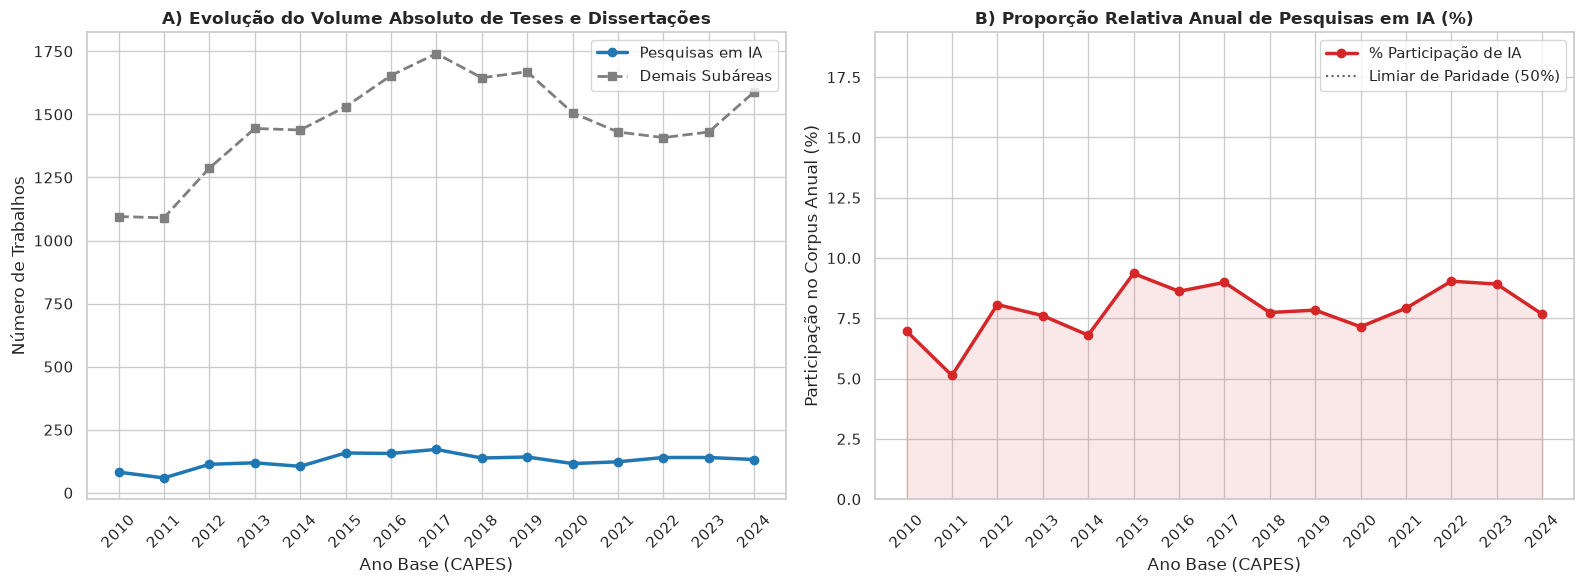

In [6]:
caminho_pasta_figuras = '../data/figuras'
os.makedirs(caminho_pasta_figuras, exist_ok=True)

# 1. Evolução dos tópicos no BERTopic (topics_over_time)
anos = df['AN_BASE'].tolist()
topicos_no_tempo = topic_model.topics_over_time(documentos, df['TOPICO_ID'].tolist(), anos)

# 2. Cálculo da Proporção Temporal Anual (IA vs. Outras Subáreas)
df_temporal = df.groupby('AN_BASE').agg(
    Total_Trabalhos=('IS_IA', 'count'),
    Trabalhos_IA=('IS_IA', 'sum')
).reset_index()

df_temporal['Trabalhos_Outras'] = df_temporal['Total_Trabalhos'] - df_temporal['Trabalhos_IA']
df_temporal['Proporcao_IA (%)'] = (df_temporal['Trabalhos_IA'] / df_temporal['Total_Trabalhos'] * 100).round(2)
df_temporal['Proporcao_Outras (%)'] = (100 - df_temporal['Proporcao_IA (%)']).round(2)

print("Tabela de Evolução Temporal (Volume Absoluto e Proporção Relativa):")
display(df_temporal)

# Plotagem dupla: Volume Absoluto vs. Proporção Relativa (%)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Painel A: Volume Absoluto
axes[0].plot(df_temporal['AN_BASE'], df_temporal['Trabalhos_IA'], marker='o', linewidth=2.5, color='#1f77b4', label='Pesquisas em IA')
axes[0].plot(df_temporal['AN_BASE'], df_temporal['Trabalhos_Outras'], marker='s', linewidth=2, linestyle='--', color='#7f7f7f', label='Demais Subáreas')
axes[0].set_title('A) Evolução do Volume Absoluto de Teses e Dissertações', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ano Base (CAPES)')
axes[0].set_ylabel('Número de Trabalhos')
axes[0].set_xticks(df_temporal['AN_BASE'])
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# Painel B: Proporção Relativa (%)
axes[1].plot(df_temporal['AN_BASE'], df_temporal['Proporcao_IA (%)'], marker='o', linewidth=2.5, color='#d62728', label='% Participação de IA')
axes[1].axhline(50, color='black', linestyle=':', alpha=0.6, label='Limiar de Paridade (50%)')
axes[1].fill_between(df_temporal['AN_BASE'], df_temporal['Proporcao_IA (%)'], color='#d62728', alpha=0.1)
axes[1].set_title('B) Proporção Relativa Anual de Pesquisas em IA (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Ano Base (CAPES)')
axes[1].set_ylabel('Participação no Corpus Anual (%)')
axes[1].set_xticks(df_temporal['AN_BASE'])
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, max(df_temporal['Proporcao_IA (%)']) + 10)
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{caminho_pasta_figuras}/evolucao_temporal_ia_absoluto_e_proporcao.png', dpi=300, bbox_inches='tight')
plt.show()

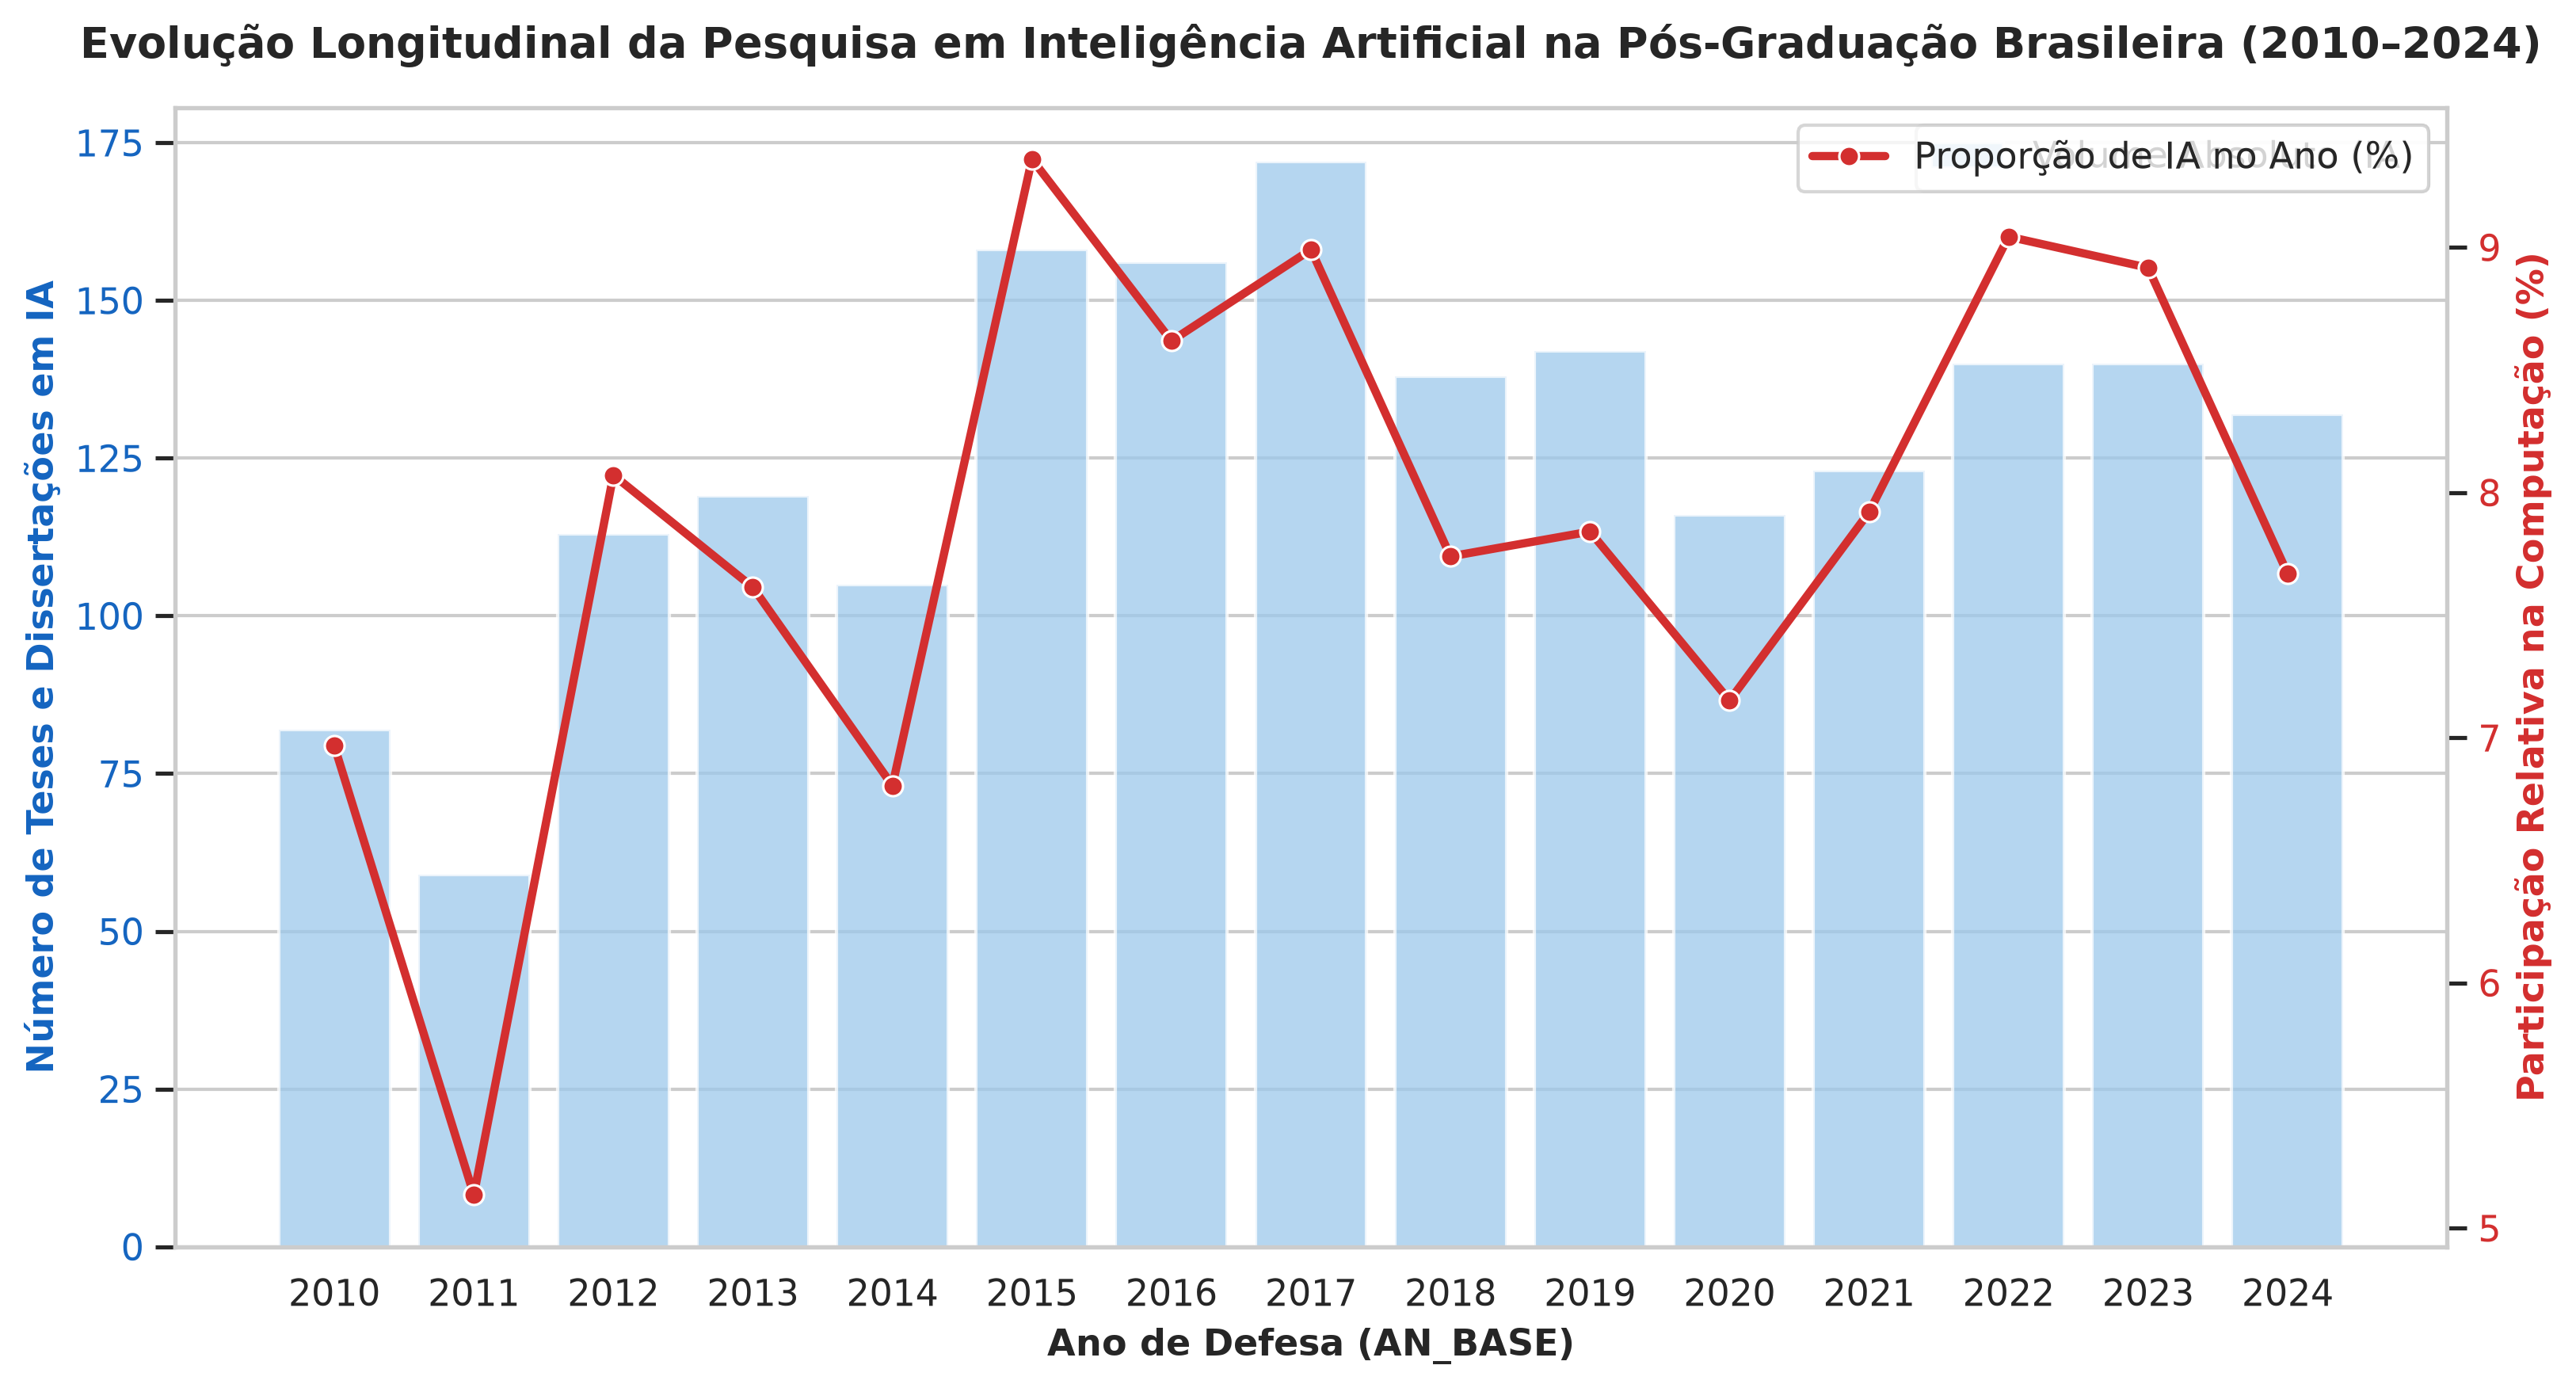

,AN_BASE,total_trabalhos,trabalhos_ia,proporcao_ia
0,2010,1177,82,6.966865
1,2011,1149,59,5.134900
2,2012,1400,113,8.071429
3,2013,1563,119,7.613564
4,2014,1543,105,6.804925
5,2015,1688,158,9.360190
6,2016,1810,156,8.618785
7,2017,1913,172,8.991113
8,2018,1783,138,7.739764
9,2019,1811,142,7.840972


In [7]:
# 2. Gráfico Estático em Alta Resolução (Padrão Artigo SBC / Educomp)
evolucao_anual = df.groupby('AN_BASE').agg(
    total_trabalhos=('IS_IA', 'count'),
    trabalhos_ia=('IS_IA', 'sum')
).reset_index()

evolucao_anual['proporcao_ia'] = (evolucao_anual['trabalhos_ia'] / evolucao_anual['total_trabalhos']) * 100

fig, ax1 = plt.subplots(figsize=(11, 6), dpi=300)

# Barras para o volume absoluto de teses/dissertações em IA
sns.barplot(data=evolucao_anual, x='AN_BASE', y='trabalhos_ia', color='#90caf9', alpha=0.75, ax=ax1, label='Volume Absoluto (IA)')
ax1.set_ylabel('Número de Teses e Dissertações em IA', fontsize=11, color='#1565c0', fontweight='bold')
ax1.set_xlabel('Ano de Defesa (AN_BASE)', fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#1565c0')

# Linha no eixo secundário para a representatividade percentual (%)
ax2 = ax1.twinx()
sns.lineplot(
    data=evolucao_anual, 
    x=range(len(evolucao_anual)), 
    y='proporcao_ia', 
    color='#d32f2f', 
    marker='o', 
    linewidth=2.5, 
    ax=ax2, 
    label='Proporção de IA no Ano (%)'
)
ax2.set_ylabel('Participação Relativa na Computação (%)', fontsize=11, color='#d32f2f', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#d32f2f')
ax2.grid(False)

plt.title('Evolução Longitudinal da Pesquisa em Inteligência Artificial na Pós-Graduação Brasileira (2010–2024)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()

# Garante que a pasta 'figuras' exista antes de salvar
caminho_pasta_figuras = '../data/figuras'
os.makedirs(caminho_pasta_figuras, exist_ok=True)
plt.savefig(f'{caminho_pasta_figuras}/grafico_evolucao_ia_2010_2024.png', dpi=300)

plt.show()

evolucao_anual

## 6. Análise Educacional: Recorte Geográfico e Nível Acadêmico
Para enriquecer a discussão pedagógica e de políticas públicas no **Educomp**, cruzamos os resultados da modelagem de tópicos com a região geográfica (`NM_REGIAO`) e o nível do curso (`NM_GRAU_ACADEMICO`).

1. Distribuição por Grau Acadêmico (Mestrado vs. Doutorado):


,GRAU_PADRONIZADO,Total_Trabalhos,Trabalhos_IA,Trabalhos_Outras,Proporcao_IA_no_Grau (%),Share_Global_IA (%)
0,Doutorado,4668,414,4254,8.87,21.85
1,Mestrado Acadêmico,17196,1409,15787,8.19,74.35
2,Mestrado Profissional,1987,72,1915,3.62,3.80



2. Distribuição Regional da Produção em IA:


,NM_REGIAO,Total_Trabalhos,Trabalhos_IA,Qtd_IES,Proporcao_IA_Interna (%),Share_Nacional_IA (%)
3,SUDESTE,10162,901,38,8.87,47.55
1,NORDESTE,6956,442,27,6.35,23.32
4,SUL,4723,362,21,7.66,19.10
0,CENTRO-OESTE,1203,136,3,11.31,7.18
2,NORTE,807,54,3,6.69,2.85



3. Síntese do Coeficiente de Gini (Interpretação: 0 = Igualdade Perfeita | 1 = Concentração Máxima):


,Recorte,Indice_Gini
0,Entre as 5 Macrorregiões (Produção Geral),0.4103
1,Entre as 5 Macrorregiões (Produção em IA),0.4222
2,Entre as 92 Instituições - IES (Produção Geral),0.5603
3,Entre as 92 Instituições - IES (Produção em IA),0.5995
4,Entre as 92 Instituições - IES (Demais Subáreas),0.5614


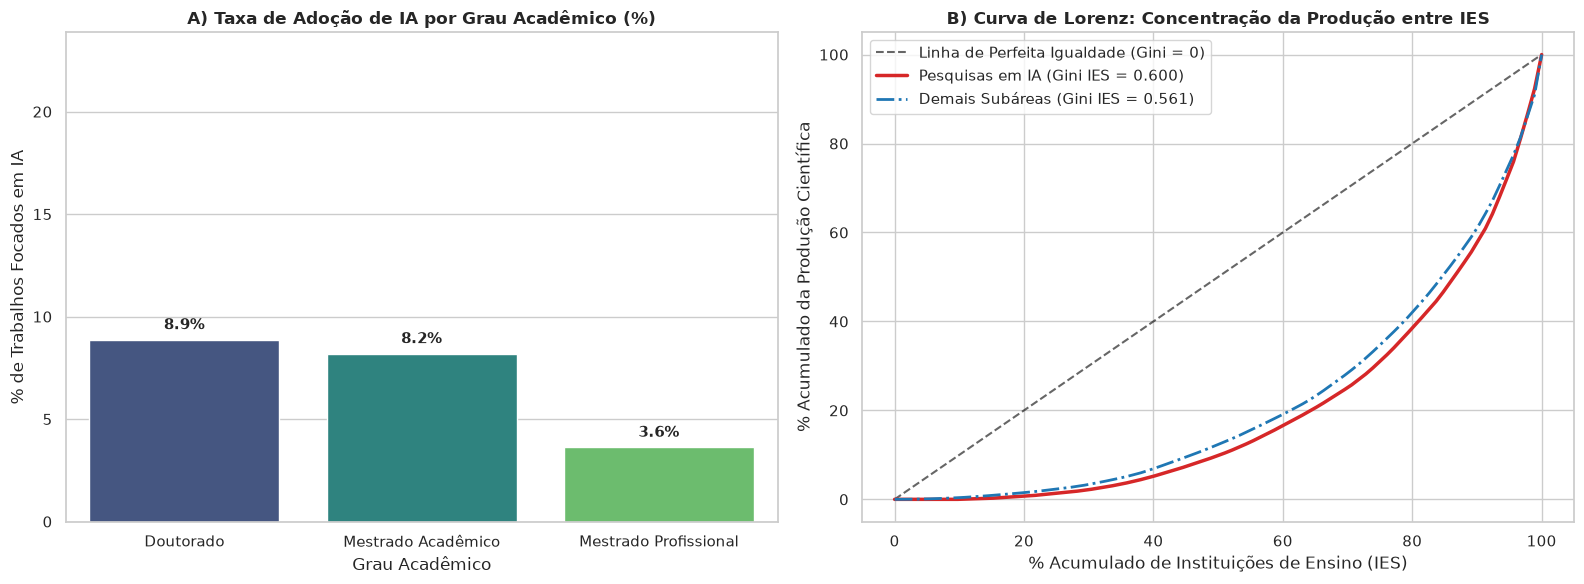

In [8]:
# 6.1 Padronização e Análise por Grau Acadêmico
def padronizar_grau(grau):
    g = str(grau).strip().upper()
    if 'DOUTORADO' in g:
        return 'Doutorado'
    elif 'PROFISSIONAL' in g:
        return 'Mestrado Profissional'
    elif 'MESTRADO' in g:
        return 'Mestrado Acadêmico'
    return 'Outros'

df['GRAU_PADRONIZADO'] = df['NM_GRAU_ACADEMICO'].apply(padronizar_grau)

df_grau = df.groupby('GRAU_PADRONIZADO').agg(
    Total_Trabalhos=('IS_IA', 'count'),
    Trabalhos_IA=('IS_IA', 'sum')
).reset_index()
df_grau['Trabalhos_Outras'] = df_grau['Total_Trabalhos'] - df_grau['Trabalhos_IA']
df_grau['Proporcao_IA_no_Grau (%)'] = (df_grau['Trabalhos_IA'] / df_grau['Total_Trabalhos'] * 100).round(2)
df_grau['Share_Global_IA (%)'] = (df_grau['Trabalhos_IA'] / df_grau['Trabalhos_IA'].sum() * 100).round(2)

print("1. Distribuição por Grau Acadêmico (Mestrado vs. Doutorado):")
display(df_grau)

# 6.2 Função Matemática Correta do Coeficiente de Gini
def calcular_gini(valores):
    """
    Calcula o Índice de Gini de forma exata para um array não-negativo.
    Gini = 0 indica igualdade perfeita (todas as unidades produzem o mesmo volume).
    Gini = 1 indica concentração absoluta (uma única unidade concentra 100% da produção).
    """
    arr = np.asarray(valores, dtype=np.float64)
    arr = arr[arr >= 0]
    if len(arr) == 0 or np.sum(arr) == 0:
        return 0.0
    # Ordenação estritamente CRESCENTE (essencial para evitar inversão de sinal)
    arr_sorted = np.sort(arr)
    n = len(arr_sorted)
    indices = np.arange(1, n + 1)
    return float((np.sum((2 * indices - n - 1) * arr_sorted)) / (n * np.sum(arr_sorted)))

# 6.3 Análise por Região e por Instituição (IES)
df_regiao = df.groupby('NM_REGIAO').agg(
    Total_Trabalhos=('IS_IA', 'count'),
    Trabalhos_IA=('IS_IA', 'sum'),
    Qtd_IES=('SG_ENTIDADE_ENSINO', 'nunique')
).reset_index().sort_values(by='Trabalhos_IA', ascending=False)

df_regiao['Proporcao_IA_Interna (%)'] = (df_regiao['Trabalhos_IA'] / df_regiao['Total_Trabalhos'] * 100).round(2)
df_regiao['Share_Nacional_IA (%)'] = (df_regiao['Trabalhos_IA'] / df_regiao['Trabalhos_IA'].sum() * 100).round(2)

# Produção por IES (incluindo IES com 0 trabalhos em IA para medir a concentração real entre programas)
df_ies = df.groupby(['SG_ENTIDADE_ENSINO', 'NM_REGIAO']).agg(
    Total_Trabalhos=('IS_IA', 'count'),
    Trabalhos_IA=('IS_IA', 'sum')
).reset_index()
df_ies['Trabalhos_Outras'] = df_ies['Total_Trabalhos'] - df_ies['Trabalhos_IA']
df_ies['Proporcao_IA (%)'] = (df_ies['Trabalhos_IA'] / df_ies['Total_Trabalhos'] * 100).round(2)
df_ies = df_ies.sort_values(by='Trabalhos_IA', ascending=False).reset_index(drop=True)

# Cálculo dos Índices de Gini (Nível Regional vs. Nível Institucional)
gini_regiao_total = calcular_gini(df_regiao['Total_Trabalhos'])
gini_regiao_ia = calcular_gini(df_regiao['Trabalhos_IA'])

gini_ies_total = calcular_gini(df_ies['Total_Trabalhos'])
gini_ies_ia = calcular_gini(df_ies['Trabalhos_IA'])
gini_ies_outras = calcular_gini(df_ies['Trabalhos_Outras'])

df_resumo_gini = pd.DataFrame([
    {'Recorte': 'Entre as 5 Macrorregiões (Produção Geral)', 'Indice_Gini': round(gini_regiao_total, 4)},
    {'Recorte': 'Entre as 5 Macrorregiões (Produção em IA)', 'Indice_Gini': round(gini_regiao_ia, 4)},
    {'Recorte': f'Entre as {len(df_ies)} Instituições - IES (Produção Geral)', 'Indice_Gini': round(gini_ies_total, 4)},
    {'Recorte': f'Entre as {len(df_ies)} Instituições - IES (Produção em IA)', 'Indice_Gini': round(gini_ies_ia, 4)},
    {'Recorte': f'Entre as {len(df_ies)} Instituições - IES (Demais Subáreas)', 'Indice_Gini': round(gini_ies_outras, 4)}
])

print("\n2. Distribuição Regional da Produção em IA:")
display(df_regiao)

print("\n3. Síntese do Coeficiente de Gini (Interpretação: 0 = Igualdade Perfeita | 1 = Concentração Máxima):")
display(df_resumo_gini)

# 6.4 Visualização: Grau Acadêmico e Curva de Lorenz (Gini por IES)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Proporção de IA por Grau Acadêmico
sns.barplot(
    data=df_grau, x='GRAU_PADRONIZADO', y='Proporcao_IA_no_Grau (%)', 
    palette='viridis', hue='GRAU_PADRONIZADO', legend=False, ax=axes[0]
)
axes[0].set_title('A) Taxa de Adoção de IA por Grau Acadêmico (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Grau Acadêmico')
axes[0].set_ylabel('% de Trabalhos Focados em IA')
axes[0].set_ylim(0, max(df_grau['Proporcao_IA_no_Grau (%)']) + 15)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5), textcoords='offset points')

# Gráfico 2: Curva de Lorenz da Concentração Institucional (IES)
ias_ordenadas = np.sort(df_ies['Trabalhos_IA'].values)
outras_ordenadas = np.sort(df_ies['Trabalhos_Outras'].values)

pop_acumulada = np.linspace(0, 100, len(df_ies) + 1)
lorenz_ia = np.concatenate([[0], np.cumsum(ias_ordenadas) / np.sum(ias_ordenadas) * 100])
lorenz_outras = np.concatenate([[0], np.cumsum(outras_ordenadas) / np.sum(outras_ordenadas) * 100])

axes[1].plot(pop_acumulada, pop_acumulada, linestyle='--', color='black', alpha=0.6, label='Linha de Perfeita Igualdade (Gini = 0)')
axes[1].plot(pop_acumulada, lorenz_ia, linewidth=2.5, color='#d62728', label=f'Pesquisas em IA (Gini IES = {gini_ies_ia:.3f})')
axes[1].plot(pop_acumulada, lorenz_outras, linewidth=2, color='#1f77b4', linestyle='-.', label=f'Demais Subáreas (Gini IES = {gini_ies_outras:.3f})')
axes[1].set_title('B) Curva de Lorenz: Concentração da Produção entre IES', fontsize=12, fontweight='bold')
axes[1].set_xlabel('% Acumulado de Instituições de Ensino (IES)')
axes[1].set_ylabel('% Acumulado da Produção Científica')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{caminho_pasta_figuras}/analise_grau_academico_e_curva_lorenz_gini.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Exportação da Base Rotulada para a Etapa 3 (Classificação Supervisionada)
Salvamos o dataset enriquecido com as colunas `TOPICO_ID`, `TOPICO_NOME` e `IS_IA` diretamente em formato compactado `.csv.gz` (respeitando o limite do GitHub). 

In [10]:
# ==============================================================================
# 7. EXPORTAÇÃO DA BASE ROTULADA (.CSV.GZ) E RELATÓRIO CONSOLIDADO (.XLSX)
# ==============================================================================

caminho_saida_csv = '../data/dados_capes_topicos_ia.csv.gz'
caminho_info_csv = '../data/tabela_resumo_topicos_bertopic.csv.gz'
caminho_saida_excel = '../data/relatorio_analise_bertopic_capes.xlsx'

# 1. Salva os arquivos compactados para alimentar a Etapa 3 (Classificação Supervisionada)
df.to_csv(caminho_saida_csv, index=False, encoding='utf-8', compression='gzip')
info_topicos.to_csv(caminho_info_csv, index=False, encoding='utf-8', compression='gzip')
print(f"Bases CSV salvas com sucesso em:\n - {caminho_saida_csv}\n - {caminho_info_csv}")

# 2. Exporta todas as tabelas analíticas para um arquivo Excel (.xlsx) multi-abas
with pd.ExcelWriter(caminho_saida_excel, engine='openpyxl') as writer:
    info_topicos.to_excel(writer, sheet_name='Resumo_Topicos_BERTopic', index=False)
    df_topicos_ia_detalhes.to_excel(writer, sheet_name='Topicos_IA_Selecionados', index=False)
    df_temporal.to_excel(writer, sheet_name='Evolucao_Temporal_Proporcao', index=False)
    df_grau.to_excel(writer, sheet_name='Grau_Academico', index=False)
    df_regiao.to_excel(writer, sheet_name='Disparidade_Regional', index=False)
    df_resumo_gini.to_excel(writer, sheet_name='Indices_de_Gini', index=False)
    df_ies.to_excel(writer, sheet_name='Ranking_Instituicoes_IES', index=False)
    
    # Exporta metadados de todos os trabalhos (sem o texto bruto longo para manter a planilha leve)
    colunas_metadados = ['AN_BASE', 'NM_REGIAO', 'SG_ENTIDADE_ENSINO', 'NM_PROGRAMA', 
                         'GRAU_PADRONIZADO', 'NM_PRODUCAO', 'TOPICO_ID', 'TOPICO_NOME', 'IS_IA']
    
    # Filtro Regex: Limpa caracteres de controle ASCII que causam o IllegalCharacterError no Excel
    df_excel = df[colunas_metadados].replace(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]', '', regex=True)
    
    df_excel.to_excel(writer, sheet_name='Catalogo_Trabalhos_Rotulados', index=False)

print(f"\nPlanilha Excel gerada com sucesso em: {caminho_saida_excel}")

Bases CSV salvas com sucesso em:
 - ../data/dados_capes_topicos_ia.csv.gz
 - ../data/tabela_resumo_topicos_bertopic.csv.gz

Planilha Excel gerada com sucesso em: ../data/relatorio_analise_bertopic_capes.xlsx
